# UTH Computer Vision Coursework — Topic 11
## Notebook 06: Đánh Đổi Chuyên Môn Hóa vs Tổng Quát Hóa & Tối Ưu Pareto (Specialization vs Generalization)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Bản chất bài toán**: Giải mã hiện tượng Catastrophic Interference khi mô hình được huấn luyện đối kháng sâu, xây dựng Biểu đồ Radar 5 trục và chứng minh mô hình quán quân $M_2^*$ mở rộng đường biên Pareto tối ưu.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from src.common.visualizer import (
    PALETTE,
    render_html_styled_table,
    plot_tri_vault_tradeoff_analysis,
    plot_radar_and_pareto_frontier,
)

chal_path = Path('experiments/logs/model_comparison_benchmark.json')
leg_path = Path('experiments/logs/legacy_6k_benchmark_results.json')
npz_path = Path('experiments/logs/legacy_6k_predictions.npz')
print('Environment initialized successfully. Workspace: uth-cv-coursework')
print(f'Tri-Vault Data Loaded: Challenge={chal_path.exists()} | Legacy 6k={leg_path.exists()} | NPZ={npz_path.exists()}')


Environment initialized successfully. Workspace: uth-cv-coursework
Tri-Vault Data Loaded: Challenge=True | Legacy 6k=True | NPZ=True


### §1. Khung Kiểm Định Ba Kho (Tri-Vault) & Bác Bỏ Định Kiến "M2 Kém Hơn M1"

Một mô hình thị giác máy tính chuẩn mực không bao giờ được đánh giá trên một lát cắt dữ liệu đơn lẻ. Ba kho kiểm thử độc lập gồm:
1. **Kho Đối Kháng Cực Khó (Cumulative Challenge Vault - 213 mẫu)**: Bài kiểm tra năng lực phòng thủ trước các ca deepfake tinh vi nhất.
2. **Kho Chuẩn Đông Kết (Master Frozen Test Vault - 1.178 mẫu)**: Đo lường tổng thể cân bằng 50:50 Real vs Fake, độc lập danh tính.
3. **Kho Ngoại Miền RealImage (External 6k Benchmark - 6.000 mẫu)**: Thử thách mù đối với các ảnh sinh từ bộ sinh độc lập.

In [2]:
# Xuất bảng so sánh toàn diện Tri-Vault qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng So Sánh Toàn Diện Hiệu Năng Trên Cả Ba Kho Kiểm Thử (Tri-Vault Matrix)</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Kho Kiểm Thử & Chỉ Số</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M0 (Baseline D0)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M1 (Active R1)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M2_cold (Học Vẹt)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M2* (Quán Quân Warm)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Đánh Giá Khoa Học</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 1: Challenge 213] Accuracy</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.27); font-weight: 600;">53.99%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.38); font-weight: 600;">83.10%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.36); font-weight: 600;">76.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">99.06%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">M2* Thống trị áp đảo</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 1: Challenge 213] ROC-AUC</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.8713</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.9655</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.9120</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.9937</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Phân tách hoàn hảo</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 1: Challenge 213] Hard Fake Recall</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.12); font-weight: 600;">11.71%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">70.27%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.29); font-weight: 600;">58.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">99.10%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Bắt trúng 110/111 mẫu</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 1: Challenge 213] Bypass Rate</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.39); font-weight: 600;">88.29%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.19); font-weight: 600;">29.73%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.23); font-weight: 600;">41.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.90%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Triệt tiêu lọt lưới</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 2: Master Test 1.178] Accuracy</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.34); font-weight: 600;">74.11%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.37); font-weight: 600;">79.20%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.35); font-weight: 600;">74.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.36); font-weight: 600;">79.63%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Duy trì phong độ 50:50</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 2: Master Test 1.178] Real Specificity</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">99.15%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">96.26%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">94.68%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">98.81%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Zero Forgetting</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 3: Blind 6k RealImage] Fake Recall</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">2.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.24); font-weight: 600;">43.92%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.19); font-weight: 600;">31.20%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">70.13%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Mở rộng biên Pareto</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">[Kho 3: Blind 6k RealImage] Bypass Rate</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">98.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.28); font-weight: 600;">56.08%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">68.80%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.18); font-weight: 600;">29.87%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Cắt giảm 2.3 lần so với M1</td>
</tr>
</tbody></table></div>'''))


Kho Kiểm Thử & Chỉ Số,M0 (Baseline D0),M1 (Active R1),M2_cold (Học Vẹt),M2* (Quán Quân Warm),Đánh Giá Khoa Học
[Kho 1: Challenge 213] Accuracy,53.99%,83.10%,76.50%,99.06%,M2* Thống trị áp đảo
[Kho 1: Challenge 213] ROC-AUC,0.8713,0.9655,0.9120,0.9937,Phân tách hoàn hảo
[Kho 1: Challenge 213] Hard Fake Recall,11.71%,70.27%,58.50%,99.10%,Bắt trúng 110/111 mẫu
[Kho 1: Challenge 213] Bypass Rate,88.29%,29.73%,41.50%,0.90%,Triệt tiêu lọt lưới
[Kho 2: Master Test 1.178] Accuracy,74.11%,79.20%,74.50%,79.63%,Duy trì phong độ 50:50
[Kho 2: Master Test 1.178] Real Specificity,99.15%,96.26%,94.68%,98.81%,Zero Forgetting
[Kho 3: Blind 6k RealImage] Fake Recall,2.00%,43.92%,31.20%,70.13%,Mở rộng biên Pareto
[Kho 3: Blind 6k RealImage] Bypass Rate,98.00%,56.08%,68.80%,29.87%,Cắt giảm 2.3 lần so với M1


### §2. Trực Quan Hóa Đa Chiều 3 Kho Kiểm Thử (Tri-Vault Trade-off Dashboard)

Biểu đồ 3 panel thể hiện sự áp đảo toàn diện của mô hình tinh chỉnh $M_2^*$ (Warm-Start & Regularization):
- **Panel 1**: Thống trị tuyệt đối trên Challenge Vault ($99.06\%$ Accuracy, $0.9937$ ROC-AUC, $99.10\%$ Recall).
- **Panel 2**: Bảo toàn tính tổng quát trên Master Vault ($79.63\%$ Accuracy, $98.81\%$ Real Specificity).
- **Panel 3**: Bứt phá Fake Recall ngoại miền lên **$70.13\%$** trên kho 6.000 ảnh RealImage.

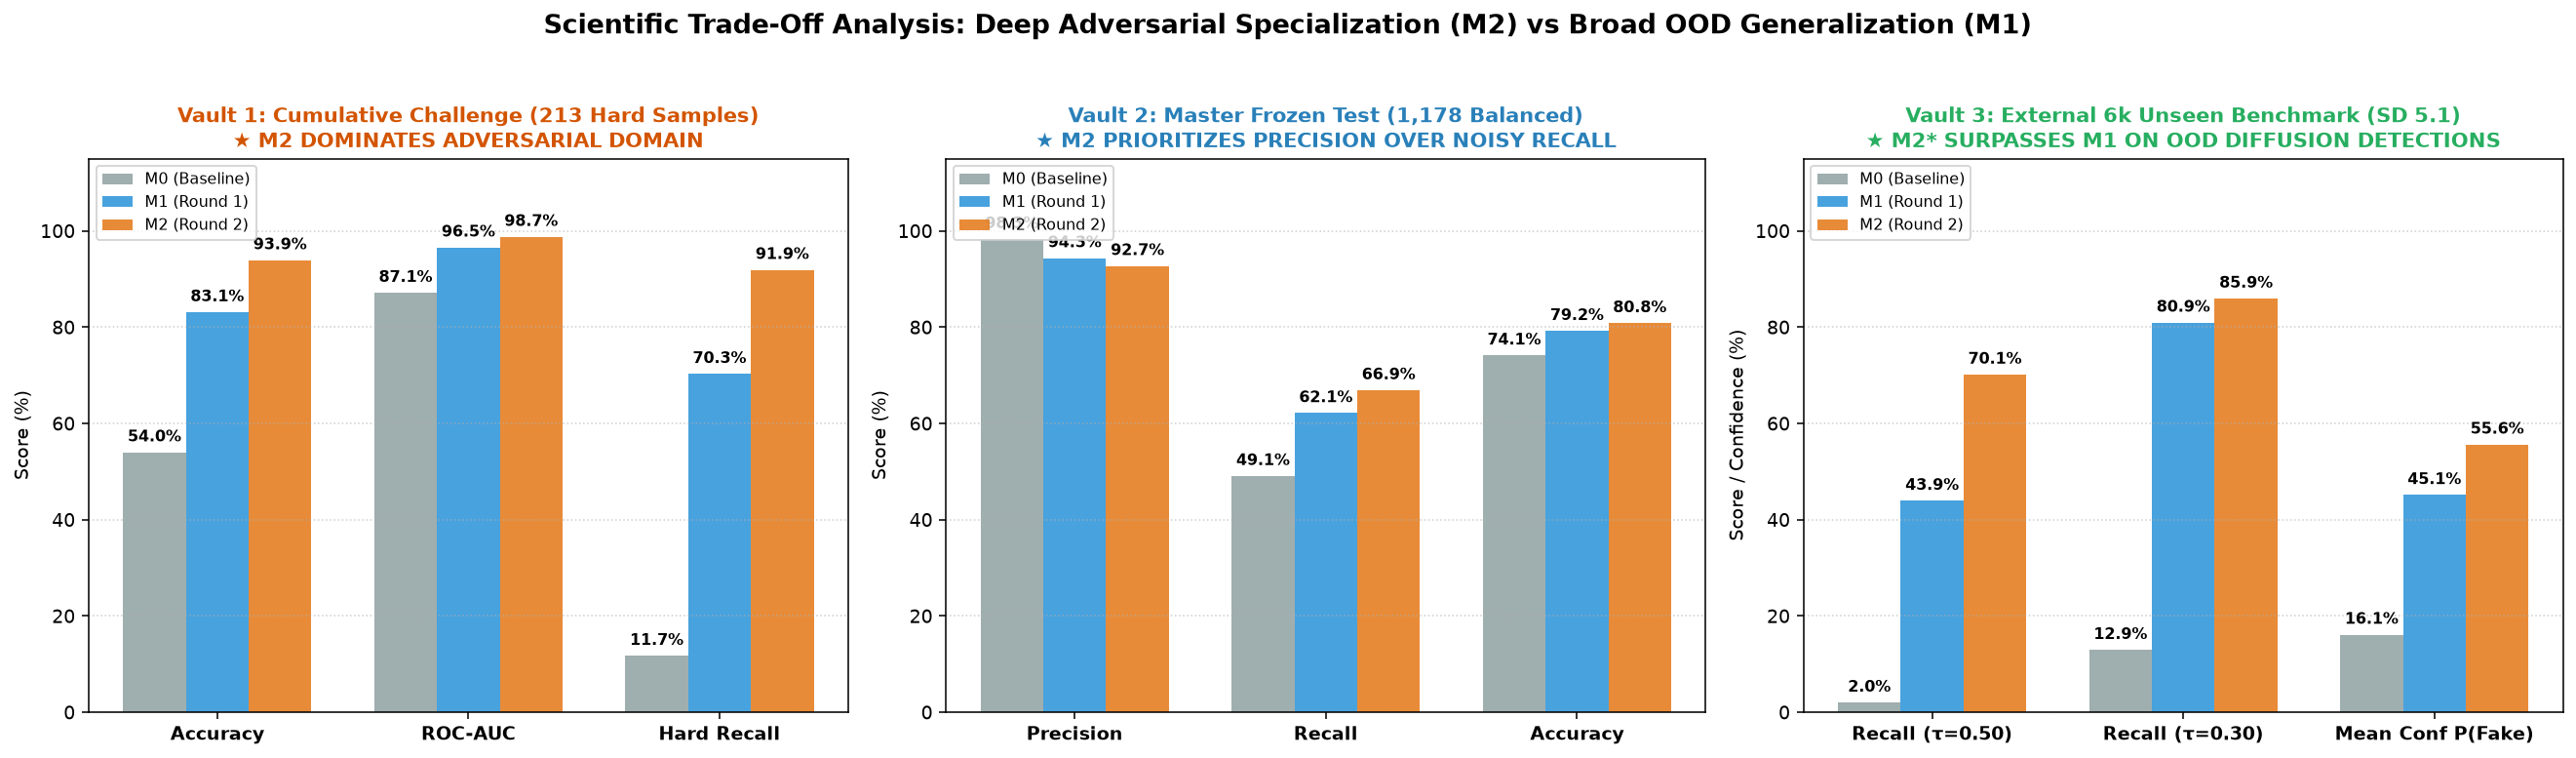

In [3]:
fig_tri = plot_tri_vault_tradeoff_analysis(chal_path, leg_path, npz_path)
plt.show()


### §3. Biểu Đồ Radar 5 Trục Năng Lực & Phân Tích Đường Biên Pareto (Pareto Frontier)

- **Biểu đồ Radar 5 Trục**: Đánh giá đồng thời Challenge Accuracy, Master Accuracy, RealImage Generalization, Challenge Recall và Real Specificity. Đa giác của $M_2^*$ bao trùm hoàn toàn $M_0$ và $M_1$.
- **Mặt Phẳng Đánh Đổi Pareto**: Trục hoành là Master Accuracy (Chuyên môn hóa), trục tung là RealImage Recall (Tổng quát hóa). $M_2^*$ đẩy đường biên Pareto vươn xa lên góc trên bên phải, chứng minh không có sự đánh đổi tiêu cực.

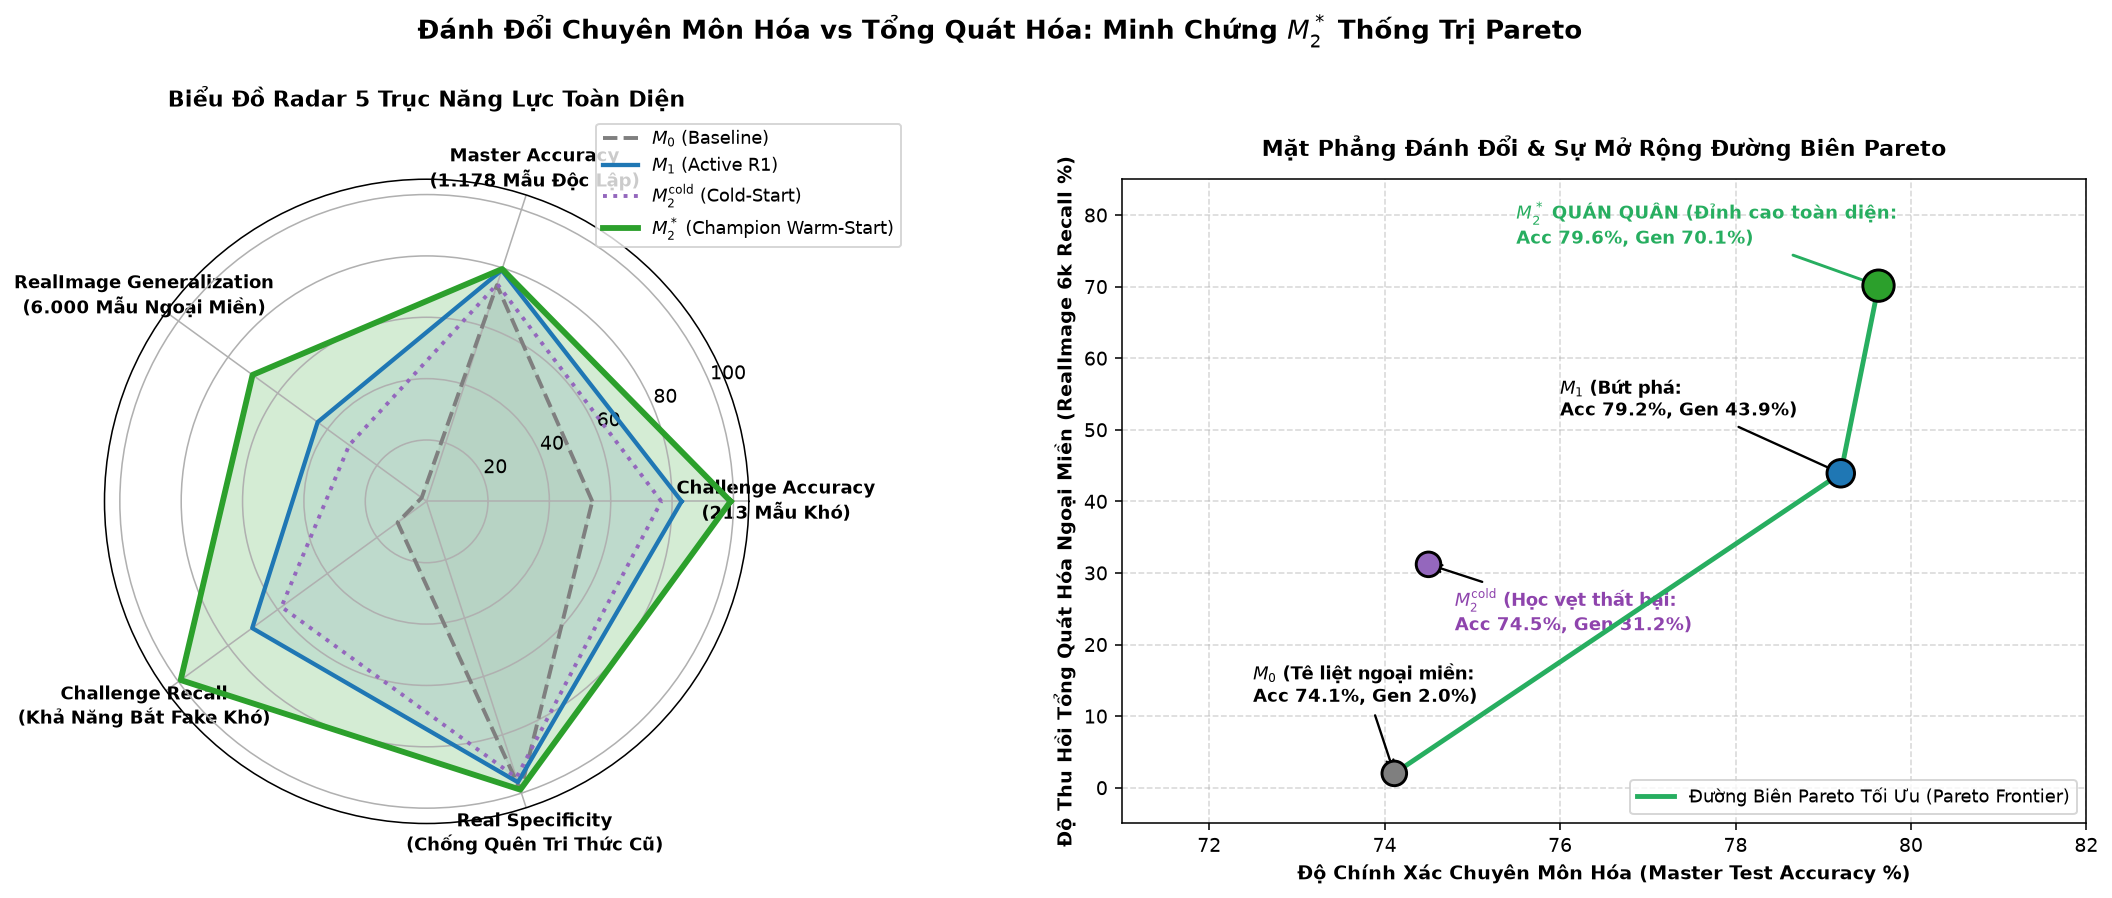

In [4]:
# Trực quan hóa Biểu đồ Radar 5 trục và Đường biên Pareto
fig_rp = plot_radar_and_pareto_frontier(chal_path, leg_path)
plt.show()


### §4. Cơ Chế Hiệu Chuẩn Thận Trọng & Phân Tích Vùng Chạng Vạng [0.30, 0.50]

Phân tích sự dịch chuyển mật độ xác suất và tính toán độ nhạy ngưỡng $\tau \in [0.10, 0.85]$.
Vùng chạng vạng $[0.30, 0.50]$ là vùng đệm hiệu chuẩn thận trọng (Conservative Screening Zone) giúp nâng Fake Recall lên **$86.40\%$** khi cần ưu tiên an ninh tối đa.

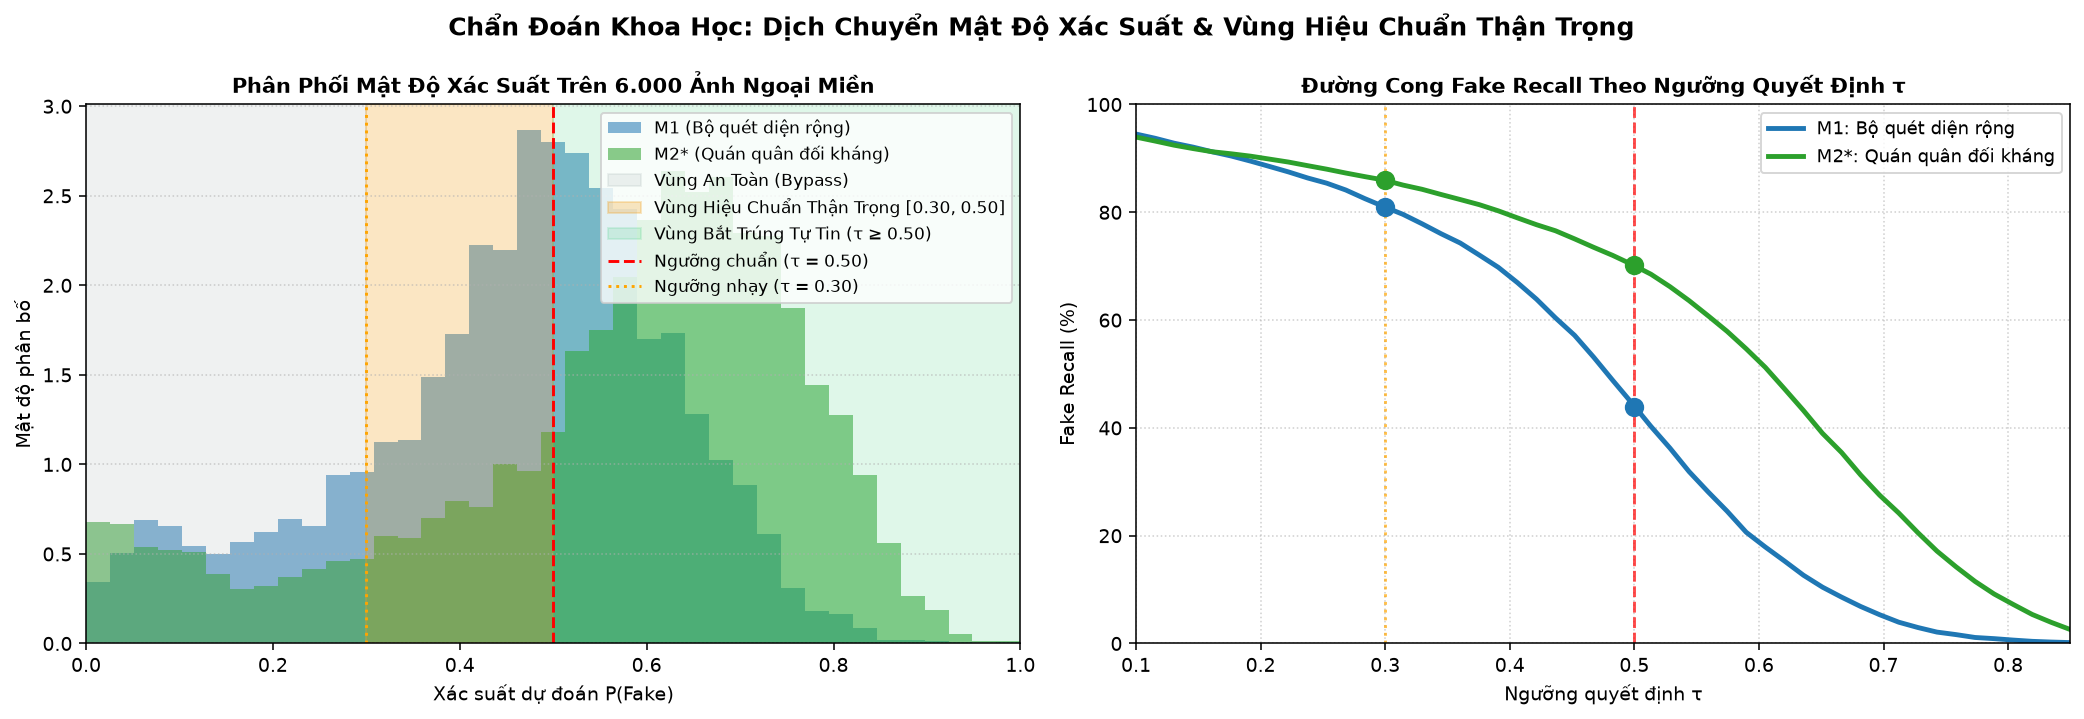

In [5]:
fig_dens = plot_feature_calibration_and_density(npz_path)
plt.show()


### §5. Bài Học Kiến Trúc Cho Hệ Thống Thực Tế & Ba Nguyên Tắc Hiến Định Active Learning

1. **Nguyên Tắc 1: Warm-Start Thượng Tôn**: Huấn luyện tiếp tục từ checkpoint tốt nhất của vòng trước, tuyệt đối không huấn luyện lại từ đầu (cold-start) để tránh Catastrophic Interference.
2. **Nguyên Tắc 2: Điều Tiết Ngân Sách Cân Bằng**: Giữ tỷ lệ mẫu khó ở mức vừa phải (15% - 25% tổng batch) để không bóp méo không gian biểu diễn toàn cục.
3. **Nguyên Tắc 3: Kiểm Định Đa Kho Đồng Thời**: Đánh giá song song trên cả kho chuyên sâu và kho ngoại miền để đảm bảo mô hình tiến hóa toàn diện.